# Section 4.2 — Census Marginal Alignment and Zero-Cell Recovery

This notebook reads the completed household-analysis artifacts without rerunning synthesis. It creates:

1. The nine-method by five-attribute macro-TVD heatmap.
2. The supplementary Negative-income zonal scatter figure.
3. Figure-ready CSV files and the combined Section 4.2 summary table.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import numpy as np
import pandas as pd
import seaborn as sns

def find_repo_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'IO/output/full_household_analysis').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate IO/output/full_household_analysis')

ROOT = find_repo_root()
ANALYSIS = ROOT / 'IO/output/full_household_analysis'
EXPERIMENTS = ROOT / 'IO/output/full_household_experiments'
FIGURES = ANALYSIS / 'section_4_2_figures'
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='paper', font_scale=1.15)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'font.family': 'DejaVu Sans'})
print(f'Repository: {ROOT}')
print(f'Figure output: {FIGURES}')

Repository: /Users/bobla/Documents/repos/PopSyn_Monash
Figure output: /Users/bobla/Documents/repos/PopSyn_Monash/IO/output/full_household_analysis/section_4_2_figures


In [2]:
METHOD_LABELS = {
    'saa_original_unrestricted': 'SAA Unrestricted',
    'saa_original_relax_empty_rows_columns': 'SAA Relaxed',
    'saa_original_seed_only': 'SAA Seed-only',
    'saa_seed_free_all_zero': 'SAA Seed-free',
    'saa_bn_pool_seed_only': 'SAA BN-pool',
    'ipf_original_weighted_seed': 'IPF Original',
    'ipf_bn_pool': 'IPF BN-pool',
    'bn_exact_hhsize': 'BN',
    'wgan_exact_hhsize': 'WGAN',
}
METHOD_ORDER = list(METHOD_LABELS)
ATTRIBUTE_ORDER = ['hhsize', 'dwelltype', 'owndwell', 'hhinc', 'totalvehs']
# ATTRIBUTE_LABELS = {
#     'hhsize': 'HH size', 'dwelltype': 'Dwelling', 'owndwell': 'Tenure',
#     'hhinc': 'Income', 'totalvehs': 'Vehicles',
# }
ATTRIBUTE_LABELS = {
    'hhsize': 'hhsize', 'dwelltype': 'dwelltype', 'owndwell': 'owndwell',
    'hhinc': 'hhinc', 'totalvehs': 'totalvehs',
}
SAA_ORDER = ['hhsize', 'dwelltype', 'owndwell', 'hhinc', 'totalvehs']

# Verify the order from every production SAA manifest.
for run_id in METHOD_ORDER[:5]:
    manifest = json.loads((EXPERIMENTS / run_id / 'repeat_01/manifest.json').read_text())
    settings = manifest['resolved_run']['settings']
    assert settings['ordered_to_adjust_atts'] == SAA_ORDER
    assert settings['last_adjustment_order'] == SAA_ORDER
print('Verified SAA order:', ' → '.join(SAA_ORDER))

Verified SAA order: hhsize → dwelltype → owndwell → hhinc → totalvehs


## Figure 4.2 — Census marginal accuracy by attribute

Cells contain canonical macro zonal TVD averaged across repeats. The square-root colour normalization improves visibility of small nonzero errors; numeric annotations retain the exact scale.

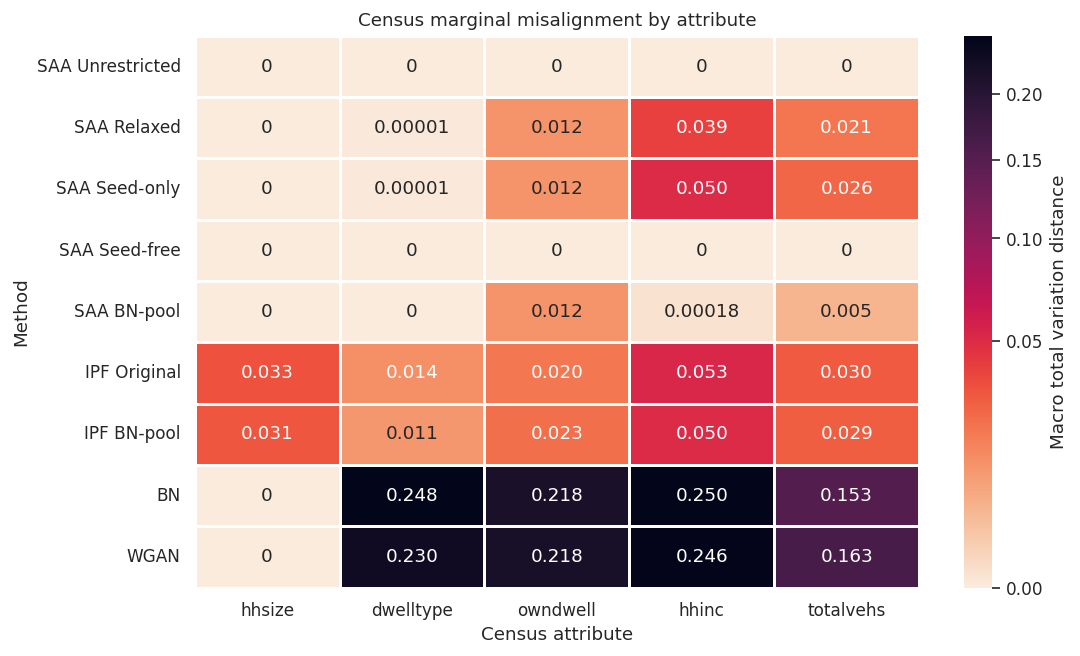

attribute,hhsize,dwelltype,owndwell,hhinc,totalvehs
run_id,,,,,
SAA Unrestricted,0.000000,0.000000,0.000000,0.000000,0.000000
SAA Relaxed,0.000000,0.000010,0.011987,0.039100,0.020513
SAA Seed-only,0.000000,0.000010,0.011987,0.050367,0.026028
SAA Seed-free,0.000000,0.000000,0.000000,0.000000,0.000000
SAA BN-pool,0.000000,0.000000,0.012205,0.000181,0.005169
IPF Original,0.032904,0.013586,0.020269,0.052722,0.030120
IPF BN-pool,0.031243,0.011194,0.022838,0.050285,0.028809
BN,0.000000,0.247792,0.217515,0.249701,0.153072
WGAN,0.000000,0.230324,0.217758,0.246235,0.163350


In [3]:
census_summary = pd.read_csv(ANALYSIS / 'census_metric_summary.csv')
macro = census_summary[
    (census_summary['evaluation'] == 'canonical')
    & (census_summary['aggregation'] == 'macro')
    & census_summary['attribute'].isin(ATTRIBUTE_ORDER)
]

heatmap = (
    macro.groupby(['run_id', 'attribute'])['total_variation'].mean()
    .unstack()
    .reindex(index=METHOD_ORDER, columns=ATTRIBUTE_ORDER)
    .rename(index=METHOD_LABELS, columns=ATTRIBUTE_LABELS)
)
heatmap.to_csv(FIGURES / 'figure_4_2_macro_tvd_heatmap_data.csv')

def tvd_label(value):
    if np.isclose(value, 0):
        return '0'
    if value < 0.001:
        return f'{value:.5f}'
    return f'{value:.3f}'

annotations = heatmap.map(tvd_label)
fig, ax = plt.subplots(figsize=(9.4, 5.6))
sns.heatmap(
    heatmap, ax=ax, cmap='rocket_r', annot=annotations, fmt='',
    linewidths=0.7, linecolor='white',
    norm=PowerNorm(gamma=0.5, vmin=0, vmax=float(heatmap.to_numpy().max())),
    cbar_kws={'label': 'Macro total variation distance'},
)
ax.set_xlabel('Census attribute')
ax.set_ylabel('Method')
ax.set_title('Census marginal misalignment by attribute')
ax.tick_params(axis='x', rotation=0)
ax.tick_params(axis='y', rotation=0)
fig.tight_layout()
for extension in ('png', 'pdf'):
    fig.savefig(FIGURES / f'figure_4_2_census_marginal_accuracy_heatmap.{extension}', bbox_inches='tight')
plt.show()
heatmap

## Main table — Overall alignment and Negative-income recovery

In [4]:
canonical = census_summary[
    (census_summary['evaluation'] == 'canonical')
    & census_summary['attribute'].isin(ATTRIBUTE_ORDER)
]
macro_repeat = (
    canonical[canonical['aggregation'] == 'macro']
    .groupby(['run_id', 'repeat'])['total_variation'].mean()
    .rename('macro_tvd')
)
weighted_repeat = (
    canonical[canonical['aggregation'] == 'household_weighted_micro']
    .groupby(['run_id', 'repeat'])['total_variation'].mean()
    .rename('weighted_tvd')
)
overall_repeat = pd.concat([macro_repeat, weighted_repeat], axis=1).reset_index()
overall = overall_repeat.groupby('run_id').agg(
    macro_tvd_mean=('macro_tvd', 'mean'), macro_tvd_sd=('macro_tvd', 'std'),
    weighted_tvd_mean=('weighted_tvd', 'mean'), weighted_tvd_sd=('weighted_tvd', 'std'),
    repeats=('repeat', 'nunique'),
)

cells = pd.read_parquet(ANALYSIS / 'census_cell_errors.parquet')
negative = cells[
    (cells['evaluation'] == 'canonical')
    & (cells['attribute'] == 'hhinc')
    & (cells['state'] == 'Negative income')
].copy()
negative_repeat = negative.groupby(['run_id', 'repeat']).agg(
    negative_income_zonal_mae=('absolute_error', 'mean'),
    exact_zones_percent=('exact_cell', lambda values: 100 * values.mean()),
).reset_index()
negative_summary = negative_repeat.groupby('run_id').agg(
    negative_income_zonal_mae_mean=('negative_income_zonal_mae', 'mean'),
    negative_income_zonal_mae_sd=('negative_income_zonal_mae', 'std'),
    exact_zones_percent_mean=('exact_zones_percent', 'mean'),
    exact_zones_percent_sd=('exact_zones_percent', 'std'),
)

section_table = (
    overall.join(negative_summary)
    .reindex(METHOD_ORDER)
    .rename(index=METHOD_LABELS)
)
section_table.to_csv(FIGURES / 'table_4_2_census_alignment_and_negative_income.csv')
section_table

,macro_tvd_mean,macro_tvd_sd,weighted_tvd_mean,weighted_tvd_sd,repeats,negative_income_zonal_mae_mean,negative_income_zonal_mae_sd,exact_zones_percent_mean,exact_zones_percent_sd
run_id,,,,,,,,,
SAA Unrestricted,0.000000,NaN,0.000000,NaN,1,0.000000,NaN,100.000000,NaN
SAA Relaxed,0.014322,NaN,0.000540,NaN,1,0.000000,NaN,100.000000,NaN
SAA Seed-only,0.017678,NaN,0.002002,NaN,1,24.795948,NaN,3.907381,NaN
SAA Seed-free,0.000000,NaN,0.000000,NaN,1,0.000000,NaN,100.000000,NaN
SAA BN-pool,0.003511,NaN,0.000070,NaN,1,0.002894,NaN,99.710564,NaN
IPF Original,0.029920,0.000213,0.007011,0.000034,10,24.795948,0.000000,3.907381,0.000000
IPF BN-pool,0.028874,0.000291,0.006449,0.000052,10,1.677279,0.054406,22.575977,1.403091
BN,0.173616,0.000285,0.138144,0.000083,10,24.757308,0.006616,3.907381,0.000000
WGAN,0.171533,0.000365,0.136709,0.000143,10,6.655861,0.144968,8.523878,0.963458


## Supplementary figure — Zonal Negative-income recovery

For repeated methods, each point uses the ten-run mean synthetic count for that POA. The panel annotations report repeat-averaged zonal MAE and exact-zone percentage.

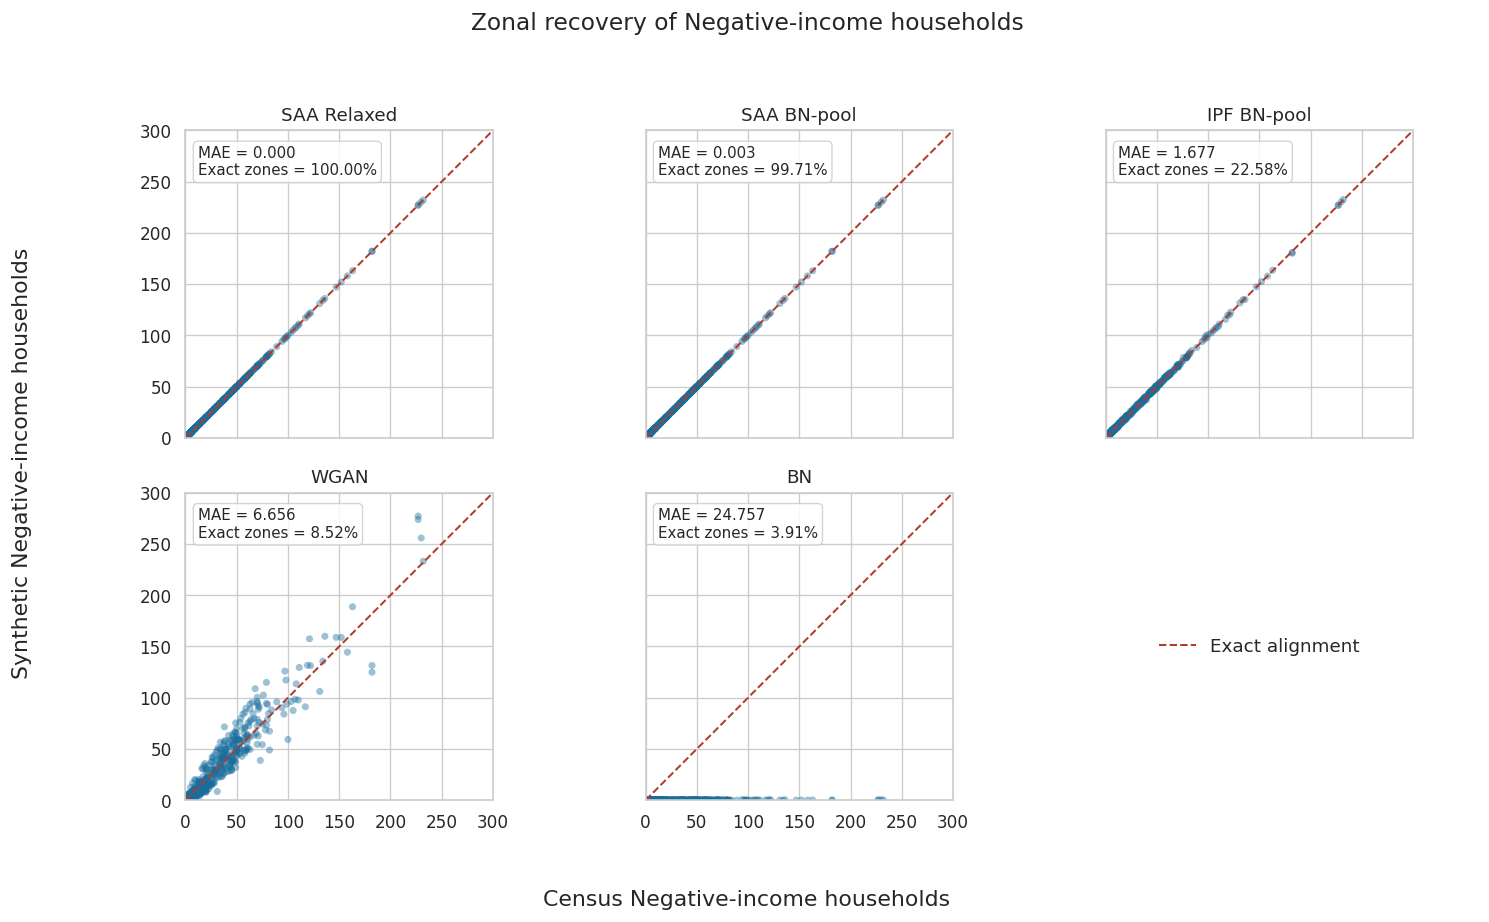

,run_id,zone_id,census_count,synthetic_count,synthetic_sd,repeats
0,bn_exact_hhsize,3000,147,0.1,0.316228,10
1,bn_exact_hhsize,3002,13,0.1,0.316228,10
2,bn_exact_hhsize,3003,20,0.1,0.316228,10
3,bn_exact_hhsize,3004,31,0.1,0.316228,10
4,bn_exact_hhsize,3006,56,0.2,0.421637,10


In [5]:
SELECTED = [
    'saa_original_relax_empty_rows_columns',
    'saa_bn_pool_seed_only',
    'ipf_bn_pool',
    'wgan_exact_hhsize',
    'bn_exact_hhsize',
]
scatter = (
    negative[negative['run_id'].isin(SELECTED)]
    .groupby(['run_id', 'zone_id'], as_index=False)
    .agg(
        census_count=('census_count', 'first'),
        synthetic_count=('synthetic_count', 'mean'),
        synthetic_sd=('synthetic_count', 'std'),
        repeats=('repeat', 'nunique'),
    )
)
scatter.to_csv(FIGURES / 'supplement_negative_income_zonal_scatter_data.csv', index=False)

panel_stats = negative_summary.reindex(SELECTED)
limit = float(scatter[['census_count', 'synthetic_count']].to_numpy().max())
limit = np.ceil(limit / 25) * 25

fig, axes = plt.subplots(2, 3, figsize=(12.5, 7.6), sharex=True, sharey=True)
axes = axes.ravel()
for ax, run_id in zip(axes, SELECTED):
    panel = scatter[scatter['run_id'] == run_id]
    ax.scatter(
        panel['census_count'], panel['synthetic_count'],
        s=18, alpha=0.42, color='#176D9C', edgecolors='none', rasterized=True,
    )
    ax.plot([0, limit], [0, limit], '--', color='#B13C2E', linewidth=1.2, label='Exact alignment')
    stat = panel_stats.loc[run_id]
    ax.text(
        0.04, 0.95,
        f"MAE = {stat['negative_income_zonal_mae_mean']:.3f}\nExact zones = {stat['exact_zones_percent_mean']:.2f}%",
        transform=ax.transAxes, va='top', ha='left', fontsize=9,
        bbox={'boxstyle': 'round,pad=0.3', 'facecolor': 'white', 'alpha': 0.86, 'edgecolor': '0.8'},
    )
    ax.set_title(METHOD_LABELS[run_id])
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)

axes[-1].axis('off')
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc='center', frameon=False, fontsize=11)
fig.supxlabel('Census Negative-income households', y=0.01)
fig.supylabel('Synthetic Negative-income households', x=0.01)
fig.suptitle('Zonal recovery of Negative-income households', y=0.995, fontsize=14)
fig.tight_layout(rect=(0.02, 0.03, 1, 0.96))
for extension in ('png', 'pdf'):
    fig.savefig(FIGURES / f'supplement_negative_income_zonal_scatter.{extension}', bbox_inches='tight')
plt.show()
scatter.head()

In [6]:
print('Created files:')
for path in sorted(FIGURES.iterdir()):
    print('-', path.relative_to(ROOT))

Created files:
- IO/output/full_household_analysis/section_4_2_figures/figure_4_2_census_marginal_accuracy_heatmap.pdf
- IO/output/full_household_analysis/section_4_2_figures/figure_4_2_census_marginal_accuracy_heatmap.png
- IO/output/full_household_analysis/section_4_2_figures/figure_4_2_macro_tvd_heatmap_data.csv
- IO/output/full_household_analysis/section_4_2_figures/supplement_negative_income_zonal_scatter.pdf
- IO/output/full_household_analysis/section_4_2_figures/supplement_negative_income_zonal_scatter.png
- IO/output/full_household_analysis/section_4_2_figures/supplement_negative_income_zonal_scatter_data.csv
- IO/output/full_household_analysis/section_4_2_figures/table_4_2_census_alignment_and_negative_income.csv
